In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path
import sys, os

In [2]:
DIT_PATH = Path("/scratch/er8/cd3022/nowcast-evaluation/error-metric-data/CPDiT")
OF_PATH = Path("/scratch/er8/cd3022/nowcast-evaluation/error-metric-data/GSO_OF")

dit_files = sorted([f for f in DIT_PATH.glob("*.nc")])
of_files = sorted([f for f in OF_PATH.glob("*.nc")])

In [3]:
dit_metrics = xr.open_mfdataset(dit_files, combine="nested", concat_dim="date")
of_metrics = xr.open_mfdataset(of_files, combine="nested", concat_dim="date")

/g/data/xp65/public/apps/med_conda/envs/analysis3-25.11/lib/python3.11/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'kerchunk' loading failed:
No module named 'zarr.core.array_spec'; 'zarr.core' is not a package
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)
/jobfs/181094708.gadi-pbs/ipykernel_2085756/3023529963.py:1: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  dit_metrics = xr.open_mfdataset(dit_files, combine="nested", concat_dim="date")


(array([24., 40., 49., 43., 49., 23., 23., 14.,  3.,  4.]),
 array([  8.2080255 ,  27.46529703,  46.72256857,  65.9798401 ,
         85.23711164, 104.49438317, 123.75165471, 143.00892624,
        162.26619778, 181.52346931, 200.78074085]),
 <BarContainer object of 10 artists>)

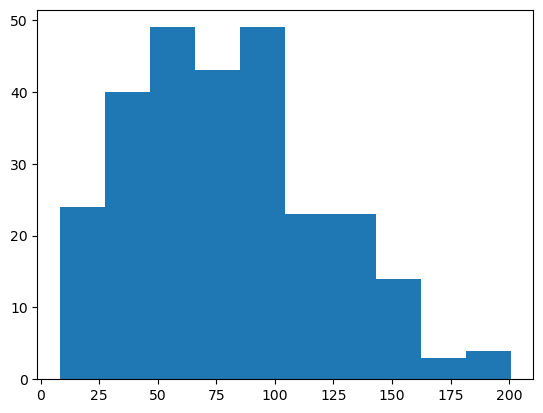

In [11]:
plt.hist(of_metrics.rmse.sel(lead_time=180))

In [12]:
of_metrics_3hr = of_metrics.sel(lead_time=180)

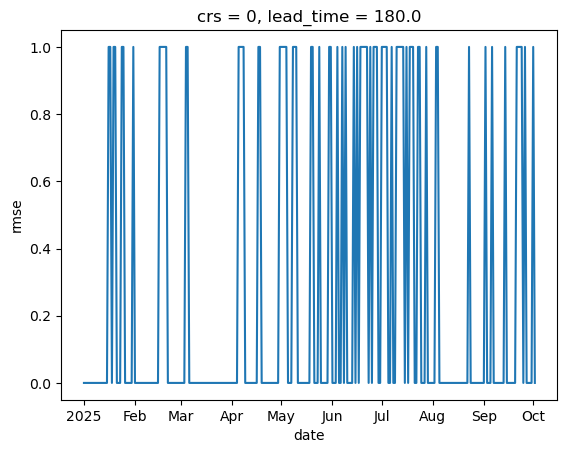

In [15]:
xr.where(of_metrics_3hr.rmse < 50, 1, 0)